# Phase 6: Recommender System Evaluation
**Mandi Watch Research Notebook 04**

This notebook evaluates the Stage 2 Recommender Engine strictly on the **held-out test split** (mid-2024 to early 2026; 26,352 pseudo-farmer simulation decisions across 87 districts and 8 commodities) per Section 10 of the Project Specification.

### Core Objectives:
1. **Realized Regret Analysis**: Measure actual regret against the hindsight Oracle Best market, and compare against Nearest Market and Historical Best baselines.
2. **Hit Rate & Ranking Correlation**: Top-1/Top-3 hit rates and Spearman rank correlation between predicted and realized rankings.
3. **Paired Hypothesis Testing**: Wilcoxon signed-rank and paired t-tests on net price advantage with Cohen's d effect sizes.
4. **Transport Rate Sensitivity**: Stress-test recommendations at 0.00, 0.15, 0.25, and 0.50 ₹/q/km.
5. **Spatial Spread vs Forecast Error**: Compare local market price dispersion with forecast MAE.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation import (
    simulate_recommender_test_period,
    compute_recommender_metrics,
    run_recommender_hypothesis_test,
    run_sensitivity_analysis,
    compute_spread_vs_forecast_error,
    plot_recommender_regret_cdf,
    plot_sensitivity_curve,
    plot_spread_vs_error
)
from src.recommender import load_cached_forecasts, load_district_centroids, load_validation_mae

print('Loaded dependencies successfully.')


Loaded dependencies successfully.


In [2]:
# 1. Load Precomputed Forecasts & Geo Coordinates
forecasts_df = load_cached_forecasts(horizon=2)
centroids_df = load_district_centroids()
val_mae_dict = load_validation_mae()

print(f'Forecasts dataset shape: {forecasts_df.shape}')
print(f'District centroids count: {len(centroids_df)}')


Forecasts dataset shape: (410080, 20)
District centroids count: 100


In [3]:
# 2. Simulate Recommender Decisions on Held-Out Test Set
sim_df = simulate_recommender_test_period(
    forecasts_df=forecasts_df,
    centroids_df=centroids_df,
    transport_rate=0.25,
    radius_km=150.0,
    road_factor=1.35
)
print(f'Total simulated decision cases: {len(sim_df)}')
sim_df.head(3)


C:\Users\DELL\OneDrive\Desktop\MandiWatch\MandiWatch\src\evaluation.py:297: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  sc, _ = spearmanr(pred_net, real_net)


Total simulated decision cases: 26352


,week_start,commodity,district,state,n_candidates,oracle_market,oracle_net_price,rec_market,rec_net_price,rec_dist_km,...,regret_near_inr,regret_near_pct,regret_hist_inr,regret_hist_pct,delta_vs_nearest_inr,delta_vs_hist_inr,is_top1_hit,is_top3_hit,spearman_corr,price_spread_inr
0,2024-11-04,Brinjal,Gwalior,Madhya Pradesh,3,Jhansi,1948.305555,Jhansi,1948.305555,126.777779,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1,1,0.50000,940.0
1,2024-11-04,Brinjal,Morena,Madhya Pradesh,2,Agra,1024.401318,Achnera,1014.401318,102.394729,...,10.000000,0.976180,0.000000,0.000000,0.000000,-10.000000,0,1,NaN,10.0
2,2024-11-04,Brinjal,Agra,Uttar Pradesh,8,Khair,1572.822956,Khair,1572.822956,108.708177,...,532.822956,33.876855,522.822956,33.241056,532.822956,522.822956,1,1,0.52381,600.0


In [4]:
# 3. Compute Summary Metrics (Regret, Hit Rates, Ranking Correlation)
summary_df, by_comm_df = compute_recommender_metrics(sim_df)
summary_df


,n_cases,mean_rec_regret_inr,median_rec_regret_inr,mean_rec_regret_pct,mean_near_regret_inr,mean_near_regret_pct,mean_hist_regret_inr,mean_advantage_vs_near_inr,top1_hit_rate_pct,top3_hit_rate_pct,mean_spearman_corr,commodity
0,26352,108.16,10.00,4.54,338.65,13.50,308.73,230.49,44.60,71.34,0.585,ALL
1,3753,246.91,65.00,6.91,736.78,20.21,680.82,489.87,39.20,64.83,0.637,Green Chilli
2,2805,160.25,0.00,6.73,601.44,24.38,481.45,441.19,54.58,83.81,0.668,Cauliflower
3,3814,113.07,20.00,4.89,409.29,16.38,380.51,296.22,44.34,63.21,0.527,Onion
4,3473,126.46,3.03,6.45,350.21,15.23,356.20,223.75,49.38,79.99,0.449,Tomato
5,3404,70.48,3.03,4.10,234.80,13.01,204.10,164.32,48.41,77.14,0.635,Brinjal
6,3718,52.80,7.05,3.67,159.52,10.74,150.36,106.72,44.89,69.66,0.618,Potato
7,1614,10.49,0.00,0.47,78.60,3.43,67.66,68.12,63.94,96.34,0.727,Paddy (Dhan)(Common)
8,3771,39.92,20.83,1.46,46.50,1.68,47.37,6.58,26.39,54.52,0.520,Wheat


In [5]:
# 4. Paired Hypothesis Testing (Recommended vs Nearest Market)
hyp_df = run_recommender_hypothesis_test(sim_df)
hyp_df[['commodity', 'n_cases', 'mean_diff_inr', 'cohens_d', 't_p_value', 'wilcoxon_p_value', 'interpretation']]


,commodity,n_cases,mean_diff_inr,cohens_d,t_p_value,wilcoxon_p_value,interpretation
0,ALL,26352,230.49,0.459,0.000000e+00,0.000000e+00,Recommended market significantly beats nearest...
1,Brinjal,3404,164.32,0.546,3.310783e-195,2.551950e-227,Recommended market significantly beats nearest...
2,Cauliflower,2805,441.19,0.592,2.555776e-185,2.511020e-209,Recommended market significantly beats nearest...
3,Green Chilli,3753,489.87,0.679,0.000000e+00,0.000000e+00,Recommended market significantly beats nearest...
4,Onion,3814,296.22,0.600,3.127250e-257,7.717021e-279,Recommended market significantly beats nearest...
5,Paddy (Dhan)(Common),1614,68.12,0.590,5.890943e-107,3.304259e-128,Recommended market significantly beats nearest...
6,Potato,3718,106.72,0.493,7.364790e-178,1.381358e-194,Recommended market significantly beats nearest...
7,Tomato,3473,223.75,0.416,8.683143e-123,4.075167e-148,Recommended market significantly beats nearest...
8,Wheat,3771,6.58,0.092,1.811316e-08,1.644230e-03,Recommended market significantly beats nearest...


In [6]:
# 5. Sensitivity Analysis Across Transport Rates
sens_df = run_sensitivity_analysis(
    forecasts_df=forecasts_df,
    centroids_df=centroids_df,
    rates=[0.0, 0.15, 0.25, 0.50],
    base_rate=0.25,
    radius_km=150.0
)
sens_df


C:\Users\DELL\OneDrive\Desktop\MandiWatch\MandiWatch\src\evaluation.py:297: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  sc, _ = spearmanr(pred_net, real_net)


C:\Users\DELL\OneDrive\Desktop\MandiWatch\MandiWatch\src\evaluation.py:297: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  sc, _ = spearmanr(pred_net, real_net)


C:\Users\DELL\OneDrive\Desktop\MandiWatch\MandiWatch\src\evaluation.py:297: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  sc, _ = spearmanr(pred_net, real_net)


C:\Users\DELL\OneDrive\Desktop\MandiWatch\MandiWatch\src\evaluation.py:297: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  sc, _ = spearmanr(pred_net, real_net)


,transport_rate,n_cases,turnover_vs_base_pct,mean_rec_regret_inr,mean_rec_regret_pct,mean_near_regret_inr,advantage_vs_nearest_inr,mean_recommended_distance_km
0,0.00,26352,8.3,107.48,4.47,355.92,248.44,94.9
1,0.15,26352,3.3,107.86,4.51,345.31,237.46,90.8
2,0.25,26352,0.0,108.16,4.54,338.65,230.49,88.0
3,0.50,26352,8.1,107.71,4.56,323.51,215.80,80.9


In [7]:
# 6. Cross-Market Price Dispersion (Spread) vs Forecast Error (MAE)
spread_df = compute_spread_vs_forecast_error(sim_df, val_mae_dict)
spread_df


,commodity,n_cases,mean_price_spread_inr,median_price_spread_inr,val_mae_inr,spread_to_mae_ratio,ranking_power,flag_spread_below_mae
0,Green Chilli,3753,1814.87,1700.0,328.41,5.53,Strong,False
1,Paddy (Dhan)(Common),1614,203.37,197.5,40.61,5.01,Strong,False
2,Cauliflower,2805,1212.17,850.0,256.77,4.72,Strong,False
3,Potato,3718,416.46,400.0,90.90,4.58,Strong,False
4,Wheat,3771,191.41,125.0,43.86,4.36,Strong,False
5,Brinjal,3404,643.18,650.0,161.28,3.99,Strong,False
6,Onion,3814,854.51,700.0,246.35,3.47,Strong,False
7,Tomato,3473,735.09,430.0,401.15,1.83,Strong,False


C:\Users\DELL\AppData\Local\Temp\ipykernel_14728\220266135.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=by_comm_df, x='commodity', y='mean_advantage_vs_near_inr', palette='viridis', ax=ax)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14728\220266135.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')


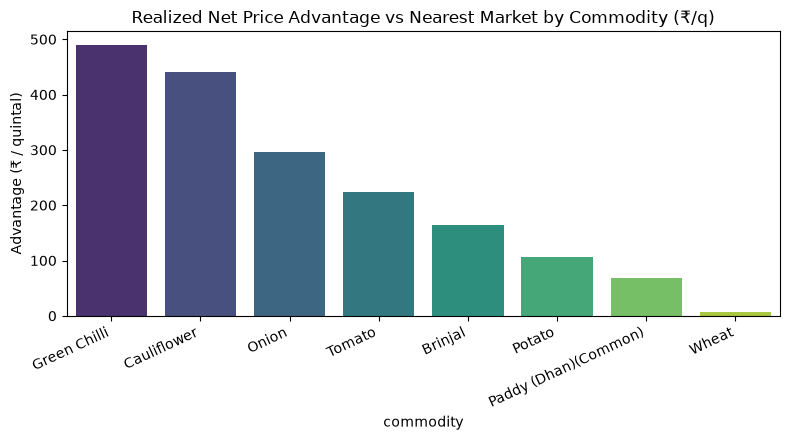

In [8]:
# 7. Visualizations
figures_dir = ROOT / 'reports' / 'figures'
plot_recommender_regret_cdf(sim_df, figures_dir / 'recommender_regret_cdf.png')
plot_sensitivity_curve(sens_df, figures_dir / 'recommender_sensitivity_curve.png')
plot_spread_vs_error(spread_df, figures_dir / 'recommender_spread_vs_mae.png')

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=by_comm_df, x='commodity', y='mean_advantage_vs_near_inr', palette='viridis', ax=ax)
ax.set_title('Realized Net Price Advantage vs Nearest Market by Commodity (₹/q)', fontsize=12)
ax.set_ylabel('Advantage (₹ / quintal)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')
plt.tight_layout()
plt.show()
